# Import libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Load the dataset

In [2]:
diabetes = load_diabetes()

X = diabetes.data
y = diabetes.target

print("Dataset shape:", X.shape)
print("Features:", diabetes.feature_names)

Dataset shape: (442, 10)
Features: ['age', 'sex', 'bmi', 'bp', 's1', 's2', 's3', 's4', 's5', 's6']


# Display the dataset

In [3]:
df = pd.DataFrame(X, columns=diabetes.feature_names)

df['Target'] = y

df.head()

,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,Target
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,151.0
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204,75.0
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,141.0
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362,206.0
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641,135.0


# Split the dataset

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (353, 10)
Testing data: (89, 10)


# Linear Regression

In [5]:
linear_model = LinearRegression()

# Decision Tree Regression

In [6]:
tree_model = DecisionTreeRegressor(random_state=42)

# Random Forest Regression

In [7]:
forest_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

# Train the models

In [8]:
linear_model.fit(X_train, y_train)

tree_model.fit(X_train, y_train)

forest_model.fit(X_train, y_train)

print("All models trained successfully!")

All models trained successfully!


# Make predictions

In [9]:
linear_pred = linear_model.predict(X_test)

tree_pred = tree_model.predict(X_test)

forest_pred = forest_model.predict(X_test)

# Calculate Performance

In [11]:
def evaluate_model(name, y_test, y_pred):
    mae = mean_absolute_error(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, y_pred)

    print("\n", name)
    print("MAE :", mae)
    print("MSE :", mse)
    print("RMSE:", rmse)
    print("R2 Score:", r2)

# Evaluate Linear Regression

In [12]:
evaluate_model(
    "Linear Regression",
    y_test,
    linear_pred
)


 Linear Regression
MAE : 42.79409467959994
MSE : 2900.193628493482
RMSE: 53.85344583676593
R2 Score: 0.4526027629719195


# Evaluate Decision Tree

In [13]:
evaluate_model(
    "Decision Tree Regression",
    y_test,
    tree_pred
)


 Decision Tree Regression
MAE : 54.52808988764045
MSE : 4976.797752808989
RMSE: 70.54642267903446
R2 Score: 0.060653981041140725


# Evaluate Random Forest

In [14]:
evaluate_model(
    "Random Forest Regression",
    y_test,
    forest_pred
)


 Random Forest Regression
MAE : 44.053033707865175
MSE : 2952.0105887640448
RMSE: 54.332408273184846
R2 Score: 0.4428225673999313


# Compare all models in a table

In [15]:
results = []

models = [
    ("Linear Regression", linear_pred),
    ("Decision Tree", tree_pred),
    ("Random Forest", forest_pred)
]

for name, prediction in models:
    mae = mean_absolute_error(y_test, prediction)
    mse = mean_squared_error(y_test, prediction)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, prediction)

    results.append([name, mae, mse, rmse, r2])

results_df = pd.DataFrame(
    results,
    columns=["Model", "MAE", "MSE", "RMSE", "R2 Score"]
)

results_df

,Model,MAE,MSE,RMSE,R2 Score
0,Linear Regression,42.794095,2900.193628,53.853446,0.452603
1,Decision Tree,54.528090,4976.797753,70.546423,0.060654
2,Random Forest,44.053034,2952.010589,54.332408,0.442823


# Plot actual vs predicted values

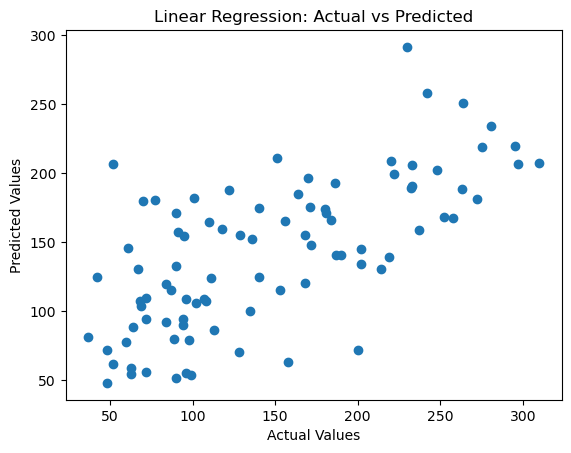

In [16]:
plt.scatter(y_test, linear_pred)

plt.xlabel("Actual Values")
plt.ylabel("Predicted Values")
plt.title("Linear Regression: Actual vs Predicted")

plt.show()

# Compare R² scores graphically

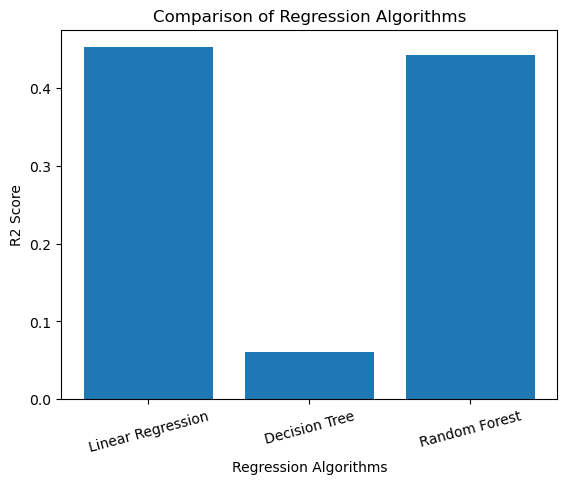

In [17]:
plt.bar(
    results_df["Model"],
    results_df["R2 Score"]
)

plt.xlabel("Regression Algorithms")
plt.ylabel("R2 Score")
plt.title("Comparison of Regression Algorithms")

plt.xticks(rotation=15)

plt.show()